In [1]:
!pip install -q segmentation-models-pytorch
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

True Tesla T4


In [2]:
!find /kaggle/input -maxdepth 3 | head -20

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/mateuszbuda
/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation


In [3]:
import glob, os
masks = sorted(glob.glob("/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/**/*_mask.tif", recursive=True))
print(len(masks), "masks")   # expect ~3929
print(masks[0])


7858 masks
/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_10_mask.tif


In [4]:
ROOT = "/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m"
masks = sorted(glob.glob(f"{ROOT}/*/*_mask.tif"))
print(len(masks), "masks")   # expect 3929
print(len({os.path.basename(os.path.dirname(m)) for m in masks}), "patients")   # expect 110


3929 masks
110 patients


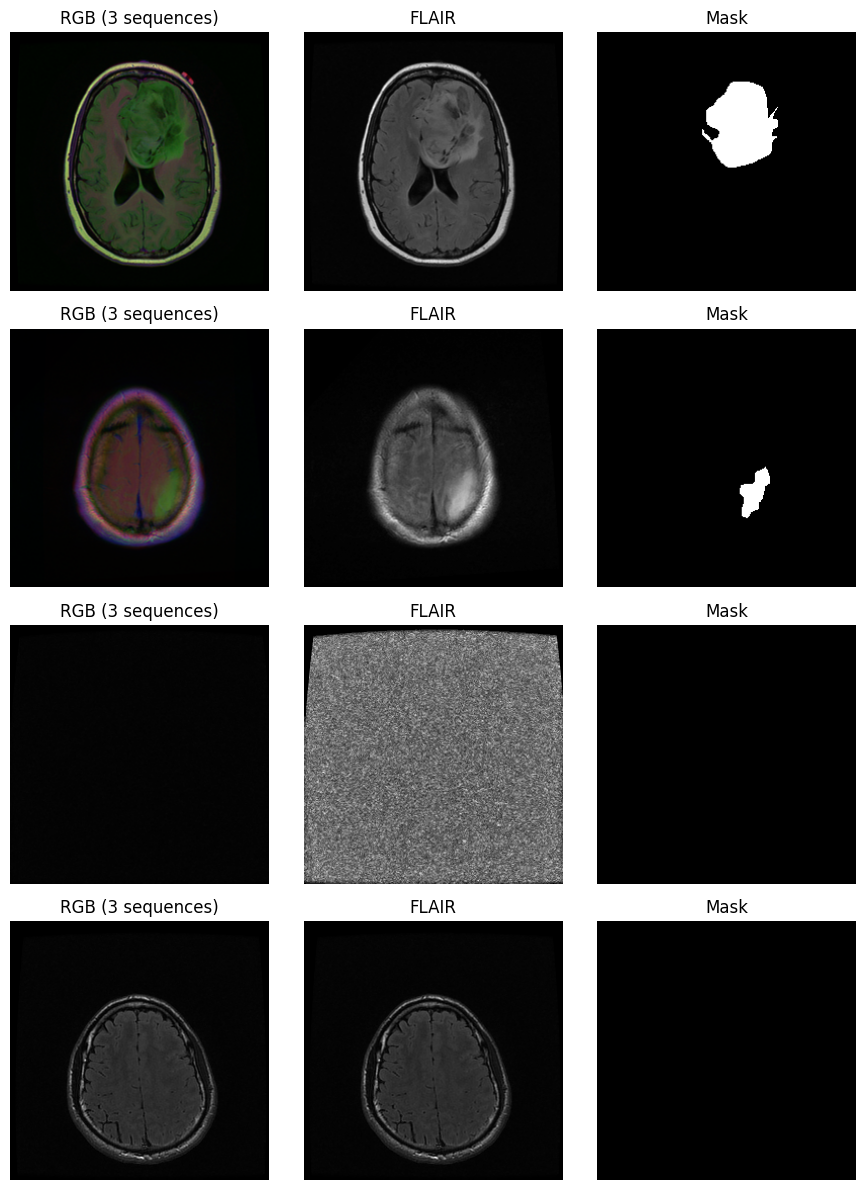

In [5]:
import numpy as np, matplotlib.pyplot as plt
from skimage.io import imread

picks = [masks[i] for i in np.random.RandomState(0).choice(len(masks), 4, replace=False)]
fig, ax = plt.subplots(4, 3, figsize=(9, 12))
for r, m in enumerate(picks):
    img, msk = imread(m.replace("_mask", "")), imread(m)
    ax[r, 0].imshow(img);                       ax[r, 0].set_title("RGB (3 sequences)")
    ax[r, 1].imshow(img[..., 1], cmap="gray");  ax[r, 1].set_title("FLAIR")
    ax[r, 2].imshow(msk, cmap="gray");          ax[r, 2].set_title("Mask")
    for a in ax[r]: a.axis("off")
plt.tight_layout()

In [6]:
import os, glob, numpy as np
from sklearn.model_selection import GroupShuffleSplit

ROOT = "/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m"
masks = sorted(glob.glob(f"{ROOT}/*/*_mask.tif"))
images = [m.replace("_mask", "") for m in masks]
patients = np.array([os.path.basename(os.path.dirname(m)) for m in masks])
masks, images = np.array(masks), np.array(images)

# 1) hold out 20% of patients for testing
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
trainval_idx, test_idx = next(gss.split(images, groups=patients))

# 2) from the rest, hold out ~15% of patients for validation
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
tr, va = next(gss2.split(images[trainval_idx], groups=patients[trainval_idx]))
train_idx, val_idx = trainval_idx[tr], trainval_idx[va]

for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(name, len(idx), "slices,", len(set(patients[idx])), "patients")

# sanity check: no patient appears in two splits
assert not set(patients[train_idx]) & set(patients[test_idx])
assert not set(patients[val_idx]) & set(patients[test_idx])
assert not set(patients[train_idx]) & set(patients[val_idx])

train 2710 slices, 74 patients
val 441 slices, 14 patients
test 778 slices, 22 patients


In [7]:
from skimage.io import imread

def flair_baseline(img, k=3):
    flair = img[..., 1].astype(float)
    brain = flair[flair > 10]                    # ignore black background
    if brain.size == 0:
        return np.zeros(flair.shape, bool)
    return flair > brain.mean() + k * brain.std()

def dice(p, t):
    return 2 * (p & t).sum() / (p.sum() + t.sum() + 1e-8)

def evaluate_baseline(idx, k=3):
    per_patient = {}
    false_alarms, empty_slices = 0, 0
    for i in idx:
        img = imread(images[i])
        gt = imread(masks[i]) > 0
        pred = flair_baseline(img, k)
        per_patient.setdefault(patients[i], ([], []))
        per_patient[patients[i]][0].append(pred)
        per_patient[patients[i]][1].append(gt)
        if gt.sum() == 0:
            empty_slices += 1
            false_alarms += pred.sum() > 0
    scores = {p: dice(np.stack(v[0]), np.stack(v[1])) for p, v in per_patient.items()}
    return scores, false_alarms, empty_slices

scores, fa, empty = evaluate_baseline(test_idx)
d = np.array(list(scores.values()))
print(f"Baseline Dice per patient: mean {d.mean():.3f}, median {np.median(d):.3f}")
print(f"False alarms on tumor-free slices: {fa}/{empty}")
print("Worst 3:", sorted(scores.items(), key=lambda x: x[1])[:3])

Baseline Dice per patient: mean 0.012, median 0.000
False alarms on tumor-free slices: 410/483
Worst 3: [(np.str_('TCGA_CS_5393_19990606'), np.float64(0.0)), (np.str_('TCGA_CS_6290_20000917'), np.float64(0.0)), (np.str_('TCGA_DU_5852_19950709'), np.float64(0.0))]


In [8]:
from scipy import ndimage as ndi
from skimage.morphology import disk, remove_small_objects

def flair_baseline(img, k=2.0, erode=12, min_area=50):
    flair = img[..., 1].astype(float)
    head = ndi.binary_fill_holes(flair > 10)
    inner = ndi.binary_erosion(head, structure=disk(erode))   # shrink inward to drop skull/scalp
    if inner.sum() < 100:
        return np.zeros(flair.shape, bool)
    vals = flair[inner]
    pred = (flair > vals.mean() + k * vals.std()) & inner
    return remove_small_objects(pred, min_area)

In [9]:
for k in [0.75, 1.0, 1.25, 1.5]:
    s, fa, empty = evaluate_baseline(val_idx, k)
    print(k, f"mean Dice {np.mean(list(s.values())):.3f}, false alarms {fa}/{empty}")

0.75 mean Dice 0.355, false alarms 242/269
1.0 mean Dice 0.409, false alarms 240/269
1.25 mean Dice 0.423, false alarms 235/269
1.5 mean Dice 0.401, false alarms 219/269


In [10]:
best_k = 1.25   # replace with your winner
scores, fa, empty = evaluate_baseline(test_idx, best_k)
d = np.array(list(scores.values()))
print(f"Baseline (k={best_k}) test Dice: mean {d.mean():.3f}, median {np.median(d):.3f}")
print(f"False alarms on tumor-free slices: {fa}/{empty}")

Baseline (k=1.25) test Dice: mean 0.328, median 0.319
False alarms on tumor-free slices: 413/483


In [11]:
from tqdm.auto import tqdm
X = np.stack([imread(p) for p in tqdm(images)])        # (3929, 256, 256, 3) uint8
Y = np.stack([imread(p) > 0 for p in tqdm(masks)])     # (3929, 256, 256) bool
print(X.shape, Y.shape)

  0%|          | 0/3929 [00:00<?, ?it/s]

  0%|          | 0/3929 [00:00<?, ?it/s]

(3929, 256, 256, 3) (3929, 256, 256)


In [12]:
import torch, random
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

# per-patient normalization: z-score each channel using that patient's brain pixels
Xn = X.astype(np.float32)
for p in np.unique(patients):
    idx = np.where(patients == p)[0]
    vol = Xn[idx]
    for c in range(3):
        ch = vol[..., c]
        brain = ch[ch > 0]
        mu, sd = brain.mean(), brain.std() + 1e-8
        vol[..., c] = np.where(ch > 0, (ch - mu) / sd, 0)
    Xn[idx] = vol

class LGG(Dataset):
    def __init__(self, idx, augment=False):
        self.idx, self.augment = idx, augment
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        x = torch.from_numpy(Xn[j]).permute(2, 0, 1)            # (3,256,256)
        y = torch.from_numpy(Y[j].astype(np.float32))[None]     # (1,256,256)
        if self.augment:
            if random.random() < 0.5: x, y = TF.hflip(x), TF.hflip(y)
            if random.random() < 0.5: x, y = TF.vflip(x), TF.vflip(y)
            a = random.uniform(-15, 15)
            x = TF.rotate(x, a, interpolation=TF.InterpolationMode.BILINEAR)
            y = TF.rotate(y, a, interpolation=TF.InterpolationMode.NEAREST)  # masks: nearest
        return x, y

train_dl = DataLoader(LGG(train_idx, True),  batch_size=16, shuffle=True,  num_workers=2)
val_dl   = DataLoader(LGG(val_idx),          batch_size=32)
xb, yb = next(iter(train_dl))
print(xb.shape, yb.shape, yb.unique())   # (16,3,256,256) (16,1,256,256) tensor([0., 1.])

torch.Size([16, 3, 256, 256]) torch.Size([16, 1, 256, 256]) tensor([0., 1.])


In [13]:
import segmentation_models_pytorch as smp

device = "cuda"
model = smp.Unet("resnet34", encoder_weights="imagenet", in_channels=3, classes=1).to(device)

dice_loss = smp.losses.DiceLoss("binary_with_logits" if False else "binary", from_logits=True)
bce = torch.nn.BCEWithLogitsLoss()
loss_fn = lambda lo, y: dice_loss(lo, y) + bce(lo, y)

opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=25)
scaler = torch.amp.GradScaler()

@torch.no_grad()
def val_dice(dl):
    model.eval()
    inter = total = 0.0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        p = (torch.sigmoid(model(x)) > 0.5).float()
        inter += (p * y).sum().item()
        total += p.sum().item() + y.sum().item()
    return 2 * inter / (total + 1e-8)

best = 0
for ep in range(25):
    model.train()
    run = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        with torch.autocast("cuda"):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        run += loss.item()
    sched.step()
    vd = val_dice(val_dl)
    if vd > best:
        best = vd
        torch.save(model.state_dict(), "/kaggle/working/best_unet.pt")
    print(f"ep {ep+1:02d} loss {run/len(train_dl):.3f} val Dice {vd:.3f} best {best:.3f}")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

ep 01 loss 0.912 val Dice 0.772 best 0.772
ep 02 loss 0.366 val Dice 0.728 best 0.772
ep 03 loss 0.254 val Dice 0.714 best 0.772
ep 04 loss 0.209 val Dice 0.767 best 0.772
ep 05 loss 0.199 val Dice 0.812 best 0.812
ep 06 loss 0.205 val Dice 0.772 best 0.812
ep 07 loss 0.180 val Dice 0.795 best 0.812
ep 08 loss 0.169 val Dice 0.755 best 0.812
ep 09 loss 0.156 val Dice 0.824 best 0.824
ep 10 loss 0.142 val Dice 0.825 best 0.825
ep 11 loss 0.143 val Dice 0.826 best 0.826
ep 12 loss 0.133 val Dice 0.826 best 0.826
ep 13 loss 0.126 val Dice 0.846 best 0.846
ep 14 loss 0.125 val Dice 0.833 best 0.846
ep 15 loss 0.130 val Dice 0.837 best 0.846
ep 16 loss 0.118 val Dice 0.834 best 0.846
ep 17 loss 0.129 val Dice 0.833 best 0.846
ep 18 loss 0.120 val Dice 0.839 best 0.846
ep 19 loss 0.113 val Dice 0.840 best 0.846
ep 20 loss 0.125 val Dice 0.841 best 0.846
ep 21 loss 0.108 val Dice 0.839 best 0.846
ep 22 loss 0.118 val Dice 0.839 best 0.846
ep 23 loss 0.112 val Dice 0.845 best 0.846
ep 24 loss 

In [16]:
import os, pandas as pd
if os.path.exists("/kaggle/working/results.csv"):
    os.remove("/kaggle/working/results.csv")          # clears duplicate rows from earlier runs

log_result("FLAIR threshold (k=1.25)", 0.328, 0.319, 413, 483)
log_result("U-Net (ResNet-34)",        0.827, 0.870, 10,  483)

!pip install -q tabulate
print(pd.read_csv("/kaggle/working/results.csv").to_markdown(index=False))

| model                    |   mean_dice |   median_dice | false_alarm_rate   |
|:-------------------------|------------:|--------------:|:-------------------|
| FLAIR threshold (k=1.25) |       0.328 |         0.319 | 413/483 (86%)      |
| U-Net (ResNet-34)        |       0.827 |         0.87  | 10/483 (2%)        |


In [17]:
model.load_state_dict(torch.load("/kaggle/working/best_unet.pt"))
model.eval()

@torch.no_grad()
def predict(idx, bs=32):
    out = []
    for i in range(0, len(idx), bs):
        x = torch.from_numpy(Xn[idx[i:i+bs]]).permute(0, 3, 1, 2).to(device)
        out.append((torch.sigmoid(model(x)) > 0.5).squeeze(1).cpu().numpy())
    return np.concatenate(out)

pred = predict(test_idx)                 # (778, 256, 256) bool
gt = Y[test_idx]
pt = patients[test_idx]

scores = {p: dice(pred[pt == p], gt[pt == p]) for p in np.unique(pt)}
d = np.array(list(scores.values()))

empty = gt.sum(axis=(1, 2)) == 0
fa = int((pred[empty].sum(axis=(1, 2)) > 0).sum())

print(f"U-Net test Dice per patient: mean {d.mean():.3f}, median {np.median(d):.3f}")
print(f"False alarms on tumor-free slices: {fa}/{empty.sum()}")
print("Worst 5:", sorted(scores.items(), key=lambda x: x[1])[:5])

log_result("U-Net (ResNet-34)", d.mean(), np.median(d), fa, int(empty.sum()))

U-Net test Dice per patient: mean 0.831, median 0.878
False alarms on tumor-free slices: 32/483
Worst 5: [(np.str_('TCGA_DU_7018_19911220'), np.float64(0.45510339156416546)), (np.str_('TCGA_DU_5852_19950709'), np.float64(0.5331960069715312)), (np.str_('TCGA_FG_8189_20030516'), np.float64(0.6996785409695336)), (np.str_('TCGA_HT_7616_19940813'), np.float64(0.7562806372547571)), (np.str_('TCGA_CS_6665_20010817'), np.float64(0.7779520970607057))]


/kaggle/working/samples/TCGA_CS_4941_19960909_11.tif (256, 256, 3) uint8 0 248
(256, 256, 3) uint8 0 255 Tumor area: 1449 pixels


(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

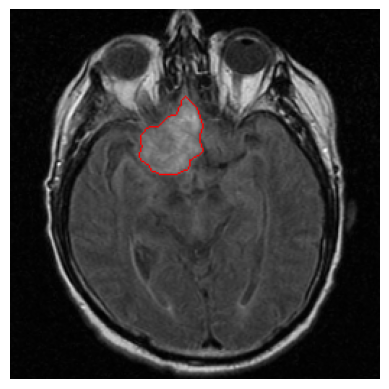

In [22]:
import glob
p = sorted(glob.glob("/kaggle/working/samples/*.tif"))[0]      # or any non-mask slice .tif
raw = imread(p)
print(p, raw.shape, raw.dtype, raw.min(), raw.max())

out, txt = segment(p)
print(out.shape, out.dtype, out.min(), out.max(), txt)

import matplotlib.pyplot as plt
plt.imshow(out); plt.axis("off")

In [23]:

import os, numpy as np, torch, gradio as gr
import segmentation_models_pytorch as smp
from skimage.io import imread
from skimage.segmentation import find_boundaries

device = "cuda" if torch.cuda.is_available() else "cpu"
WEIGHTS = "best_unet.pt"          # in Kaggle use "/kaggle/working/best_unet.pt"

model = smp.Unet("resnet34", encoder_weights=None, in_channels=3, classes=1)
model.load_state_dict(torch.load(WEIGHTS, map_location=device))
model.to(device).eval()

def segment(path):
    raw = imread(path)
    if raw.ndim == 2:
        raw = np.stack([raw] * 3, -1)
    img = raw[..., :3].astype(np.float32)
    flair = img[..., 1].copy()                     # shown to the user, before normalizing

    for c in range(3):                             # same normalization as training
        ch = img[..., c]
        brain = ch[ch > 0]
        if brain.size:
            img[..., c] = np.where(ch > 0, (ch - brain.mean()) / (brain.std() + 1e-8), 0)

    with torch.no_grad():
        x = torch.from_numpy(img).permute(2, 0, 1)[None].to(device)
        mask = (torch.sigmoid(model(x)) > 0.5)[0, 0].cpu().numpy()

    base = (255 * (flair - flair.min()) / (np.ptp(flair) + 1e-8)).astype(np.uint8)
    out = np.stack([base] * 3, -1)
    out[find_boundaries(mask, mode="outer")] = [255, 0, 0]       # red outline
    area = int(mask.sum())
    return out, (f"Tumor area: {area} pixels" if area else "No tumor detected")

demo = gr.Interface(
    fn=segment,
    inputs=gr.File(label="Upload an MRI slice (3-channel .tif/.png)", type="filepath"),
    outputs=[gr.Image(label="Tumor outline"), gr.Textbox(label="Result")],
    title="Brain tumor segmentation (U-Net)",
    description="Research demo on the LGG MRI dataset. Not a medical device.",
    examples=[[f"samples/{f}"] for f in sorted(os.listdir("samples")) if f.endswith(".tif")]
             if os.path.isdir("samples") else None,
)

if __name__ == "__main__":
    demo.launch()                  # add share=True when running in Kaggle

* Running on local URL:  http://127.0.0.1:7862
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

* Running on public URL: https://c7e2ef806c310f8292.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [20]:
import shutil, os
os.makedirs("/kaggle/working/samples", exist_ok=True)

# 6 test slices with a visible tumor (largest masks give clear demos)
has_tumor = [i for i in range(len(test_idx)) if gt[i].sum() > 500]
for i in has_tumor[::max(1, len(has_tumor)//6)][:6]:
    shutil.copy(images[test_idx[i]], "/kaggle/working/samples/")

shutil.make_archive("/kaggle/working/samples", "zip", "/kaggle/working/samples")
print(os.listdir("/kaggle/working/samples"))

['TCGA_HT_7605_19950916_28.tif', 'TCGA_HT_7882_19970125_15.tif', 'TCGA_CS_4941_19960909_11.tif', 'TCGA_FG_7637_20000922_16.tif', 'TCGA_DU_6407_19860514_20.tif', 'TCGA_DU_7306_19930512_18.tif']
